# Cours d'introduction : analyse de données avec Jupyter Notebook

Bienvenue ! Ce notebook est un cours pratique pour (re)découvrir l'analyse de données en Python, construit directement à partir de ton fichier `products(in).csv` (~49 700 produits, avec un `aisle_id` = rayon et un `department_id` = département/catégorie).

**Objectifs du cours :**
1. Charger un fichier CSV avec `pandas` et comprendre ce qu'est un `DataFrame`
2. Découvrir et **nettoyer** des données réelles (souvent sales !)
3. Explorer avec des filtres et des statistiques descriptives
4. Visualiser avec `matplotlib` / `seaborn`
5. Pratiquer avec des exercices

**Prérequis supposés :** tu connais les bases de Python (variables, listes, boucles, fonctions) mais tu n'as plus codé depuis un moment — chaque nouvelle notion sera expliquée simplement.

**Comment utiliser ce notebook :** exécute les cellules dans l'ordre avec `Shift+Entrée`. N'hésite pas à modifier le code et à réexécuter pour expérimenter, c'est le meilleur moyen d'apprendre.

> Note : ce notebook a été reconstruit après un écrasement accidentel par une version vide — si tu veux éviter que ça se reproduise, pense à faire `File > Save` régulièrement ou à garder une copie (`Analyse_product_backup.ipynb`).

In [17]:
# pandas : manipulation de tableaux de données (le coeur de ce cours)
import pandas as pd
# matplotlib : la librairie de base pour tracer des graphiques
import matplotlib.pyplot as plt
# seaborn : rend les graphiques plus jolis et ajoute des fonctions statistiques
import seaborn as sns

# Affiche les graphiques directement dans le notebook (utile hors JupyterLab récent)
%matplotlib inline
sns.set_style("whitegrid")

## 1. Charger et découvrir les données

En pandas, un fichier CSV se charge dans un **DataFrame** : imagine un tableau Excel géré par du code, avec des lignes et des colonnes nommées.

Fonctions clés à retenir :
- `pd.read_csv(chemin)` : charge un CSV dans un DataFrame
- `df.head(n)` : affiche les `n` premières lignes (par défaut 5)
- `df.shape` : donne `(nombre de lignes, nombre de colonnes)`
- `df.dtypes` : donne le type de chaque colonne (nombre entier, texte, etc.)
- `df.info()` : résumé combiné (types + valeurs manquantes + mémoire utilisée)

In [18]:
# On charge le fichier tel quel, sans rien modifier, pour voir ce qu'on obtient
df_brut = pd.read_csv("products(in).csv")

print("Dimensions (lignes, colonnes) :", df_brut.shape)
print("\nNoms des colonnes :", df_brut.columns.tolist())
df_brut.head()

Dimensions (lignes, colonnes) : (49688, 4)

Noms des colonnes : ['product_id', 'product_name', 'aisle_id', 'department_id;;;;']


,product_id,product_name,aisle_id,department_id;;;;
0,1,Chocolate Sandwich Cookies,61,19;;;;
1,2,All-Seasons Salt,104,13;;;;
2,3,Robust Golden Unsweetened Oolong Tea,94,7;;;;
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1;;;;
4,5,Green Chile Anytime Sauce,5,13;;;;


### Premier constat : ce fichier est "sale"

Tu remarques sûrement deux problèmes en regardant le résultat ci-dessus :

1. La dernière colonne s'appelle `department_id;;;;` au lieu de `department_id`, et ses valeurs ressemblent à `19;;;;` au lieu de `19`. Le fichier source contient des `;;;;` parasites en fin de chaque ligne.
2. Certaines lignes vont poser un vrai problème : quand le nom du produit contient lui-même une virgule (ex: `"Vodka, Triple Distilled, Twist of Vanilla"`), toute la ligne a été ré-encadrée par des guillemets d'une façon non standard. `pandas` s'y perd et remplit ces lignes de valeurs manquantes (`NaN`).

**C'est très courant en vrai** : les données brutes sont rarement prêtes à l'emploi. Vérifions l'ampleur du problème avec `isna()` (qui repère les valeurs manquantes/`NaN`) et `.sum()` (qui les compte par colonne).

In [19]:
# Nombre de valeurs manquantes par colonne
print(df_brut.isna().sum())

# Combien de lignes sont concernées (au moins une valeur manquante) ?
lignes_a_probleme = df_brut.isna().any(axis=1).sum()
print(f"\nLignes affectées par le bug de parsing : {lignes_a_probleme}")

product_id              0
product_name         3329
aisle_id             3329
department_id;;;;    3330
dtype: int64

Lignes affectées par le bug de parsing : 3330


## 2. Nettoyer les données

Plus de 3300 lignes sont mal lues (~6.7% du fichier) : c'est trop pour les ignorer. On va donc lire le fichier **ligne par ligne**, comme du texte brut, et réparer chaque ligne nous-mêmes avant de la donner à pandas.

Rappel Python utile ici :
- `open(fichier)` puis `for ligne in f:` permet de lire un fichier texte ligne par ligne
- une chaîne de caractères a des méthodes comme `.strip()` (enlève les espaces/retours à la ligne en trop) ou `.startswith(...)` / `.endswith(...)`
- le module `csv` sait découper correctement une ligne "au format CSV" (il gère les guillemets et les virgules à l'intérieur du texte)

Stratégie pour chaque ligne :
1. Supprimer les `;;;;` parasites en fin de ligne
2. Si la ligne entière est encadrée de guillemets (le cas des lignes "cassées"), enlever ces guillemets et remplacer les `""` par `"`
3. Découper la ligne avec le module `csv` pour obtenir proprement les 4 valeurs

In [33]:
import csv
import re


def parser_ligne(ligne):
    """Répare et découpe une ligne du fichier CSV en 4 valeurs."""
    ligne = ligne.rstrip("\r\n")
    ligne = re.sub(r";+$", "", ligne)  # on enlève les ";;;;" en fin de ligne

    if ligne.startswith('"') and ligne.endswith('"'):
        # Ligne "cassée" : toute la ligne était entre guillemets
        contenu = ligne[1:-1].replace('""', '"')
        return next(csv.reader([contenu]))
    else:
        # Ligne normale : le module csv suffit
        return next(csv.reader([ligne]))


lignes_propres = []
with open("products(in).csv", encoding="utf-8") as f:
    next(f)  # on saute la ligne d'en-tête, on la remet nous-mêmes juste après
    for ligne in f:
        lignes_propres.append(parser_ligne(ligne))

colonnes = ["product_id", "product_name", "aisle_id", "department_id"]
df = pd.DataFrame(lignes_propres, columns=colonnes)

# Les colonnes numériques sont pour l'instant du texte : on les convertit en entiers
df["product_id"] = df["product_id"].astype(int)
df["aisle_id"] = df["aisle_id"].astype(int)
df["department_id"] = df["department_id"].astype(int)

print("Dimensions après nettoyage :", df.shape)
df.head()

Dimensions après nettoyage : (49688, 4)


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [21]:
# Vérification : plus aucune valeur manquante, et on retrouve bien les lignes autrefois cassées
print(df.isna().sum())
print()
df.info()

# On retrouve bien notre produit "Vodka, Triple Distilled..." avec un nom propre
df[df["product_name"].str.contains("Vodka, Triple", na=False)]

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 49688 entries, 0 to 49687
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     49688 non-null  int64
 1   product_name   49688 non-null  str  
 2   aisle_id       49688 non-null  int64
 3   department_id  49688 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.5 MB


,product_id,product_name,aisle_id,department_id
49683,49684,"Vodka, Triple Distilled, Twist of Vanilla",124,5


## 3. Rappels Python appliqués à pandas : sélectionner et filtrer

À partir de maintenant, on travaille uniquement avec `df`, notre DataFrame propre.

- **Sélectionner une colonne** : `df["nom_colonne"]` (renvoie une `Series`, comme une liste avec un index)
- **Sélectionner plusieurs colonnes** : `df[["col1", "col2"]]`
- **Filtrer des lignes avec une condition** (comme un `if` mais appliqué à toutes les lignes d'un coup) :
  ```python
  df[df["aisle_id"] == 61]
  ```
  Ici, `df["aisle_id"] == 61` crée une colonne de `True`/`False` (un "masque booléen"), et `df[masque]` ne garde que les lignes où c'est `True`.
- **Chercher du texte dans une colonne** : `df["product_name"].str.contains("mot", case=False)` (`case=False` = insensible à la casse)

In [22]:
# Exemple 1 : tous les produits dont le nom contient "chocolate"
produits_chocolat = df[df["product_name"].str.contains("chocolate", case=False)]
print(f"{len(produits_chocolat)} produits contiennent 'chocolate'")
produits_chocolat.head()

2435 produits contiennent 'chocolate'


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
11,12,Chocolate Fudge Layer Cake,119,1
15,16,Mint Chocolate Flavored Syrup,103,19
76,77,Coconut Chocolate Chip Energy Bar,3,19
123,124,Sun Cups Dark Chocolate,45,19


In [23]:
# Exemple 2 : combiner deux conditions avec & (et) ou | (ou) -- attention, il faut des parenthèses !
produits_dept19_chocolat = df[
    (df["department_id"] == 19) & (df["product_name"].str.contains("chocolate", case=False))
]
print(f"{len(produits_dept19_chocolat)} produits contiennent 'chocolate' dans le département 19")
produits_dept19_chocolat.head()

1291 produits contiennent 'chocolate' dans le département 19


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
15,16,Mint Chocolate Flavored Syrup,103,19
76,77,Coconut Chocolate Chip Energy Bar,3,19
123,124,Sun Cups Dark Chocolate,45,19
134,135,Dark Chocolate Ice Cream Topping,103,19


## 4. Statistiques descriptives

Quelques fonctions indispensables pour prendre la température d'un jeu de données :

- `df.describe()` : statistiques (moyenne, min, max, quartiles...) pour les colonnes numériques
- `df["col"].nunique()` : nombre de valeurs **uniques** dans une colonne
- `df["col"].value_counts()` : compte combien de fois chaque valeur apparaît (très utile pour des catégories comme `department_id`)

Note : ici, `product_id`, `aisle_id` et `department_id` sont des **identifiants** (des codes), pas vraiment des quantités à moyenner — `describe()` est donc surtout intéressant pour comprendre l'étendue des ids et compter les catégories, pas pour interpréter une "moyenne de department_id" qui n'aurait pas de sens.

In [24]:
print("Nombre de départements distincts :", df["department_id"].nunique())
print("Nombre de rayons (aisles) distincts :", df["aisle_id"].nunique())
print()

# Top 10 des départements avec le plus de produits référencés
top_departements = df["department_id"].value_counts().head(10)
top_departements

Nombre de départements distincts : 21
Nombre de rayons (aisles) distincts : 134



department_id
11    6563
19    6264
13    5371
7     4365
1     4007
16    3449
17    3085
15    2092
9     1858
4     1684
Name: count, dtype: int64

## 5. Visualisation avec matplotlib / seaborn

Une bonne visualisation vaut mieux qu'un tableau de chiffres. Deux façons courantes de tracer un graphique :

- `plt.plot(...)`, `plt.bar(...)` etc. (matplotlib "pur", plus manuel)
- `sns.barplot(...)`, `sns.histplot(...)` etc. (seaborn, souvent plus simple pour des données pandas)

Astuce : `df["col"].value_counts()` renvoie une `Series` qu'on peut tracer directement avec `.plot(kind="bar")`.

> Remarque : `department_id` et `aisle_id` sont des codes numériques — ce fichier ne contient pas les noms des départements/rayons. Si tu as un jour les fichiers `departments.csv` / `aisles.csv` associés (dataset "Instacart"), on pourrait faire une **jointure** (`pd.merge`) pour afficher les vrais noms à la place des numéros.

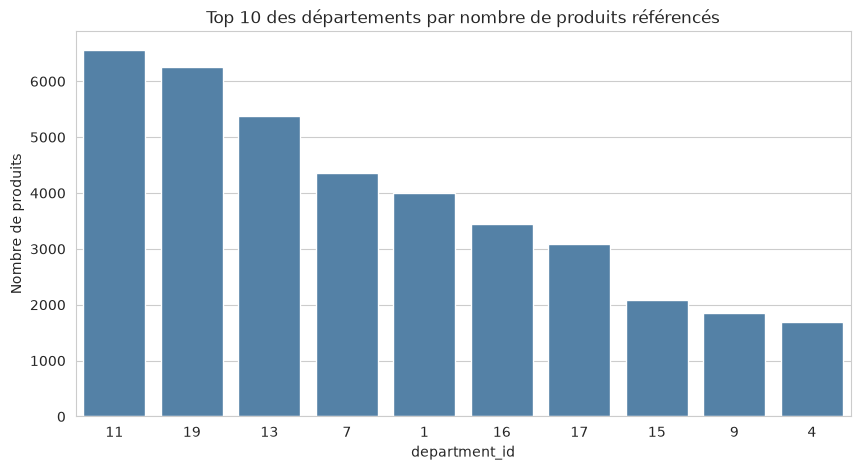

In [25]:
# Graphique en barres : les 10 départements avec le plus de produits
plt.figure(figsize=(10, 5))
sns.barplot(x=top_departements.index.astype(str), y=top_departements.values, color="steelblue")
plt.xlabel("department_id")
plt.ylabel("Nombre de produits")
plt.title("Top 10 des départements par nombre de produits référencés")
plt.show()

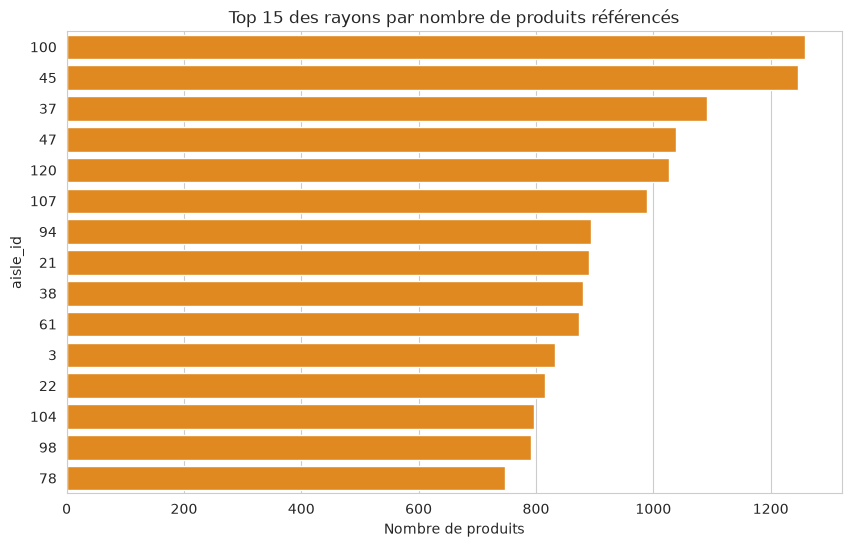

In [26]:
# Même idée pour les 15 rayons (aisles) les plus fournis
top_rayons = df["aisle_id"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_rayons.values, y=top_rayons.index.astype(str), color="darkorange", orient="h")
plt.xlabel("Nombre de produits")
plt.ylabel("aisle_id")
plt.title("Top 15 des rayons par nombre de produits référencés")
plt.show()

## exercices

Voici une série d'exercices, du plus simple au plus difficile. Les exercices **1 à 3** sont corrigés juste en dessous (essaie de les faire toi-même d'abord, puis compare). Les exercices **4 à 7** restent à faire : ajoute des cellules de code pour les résoudre, tout ce dont tu as besoin a été montré plus haut dans ce notebook.

1. **Échauffement** : combien y a-t-il de produits au total dans `df` ?
2. **Filtrage** : trouve tous les produits dont le nom contient le mot `"Organic"`. Combien y en a-t-il ?
3. **Filtrage combiné** : trouve les produits du rayon (`aisle_id`) 37 dont le nom contient `"Ice Cream"`.
4. **Comptage** : quel est le `aisle_id` qui contient le plus de produits (le vrai numéro 1, pas juste dans le top 15) ? Indice : `.value_counts().idxmax()`.
5. **Nouvelle colonne** : crée une colonne `nom_longueur` qui contient la longueur (nombre de caractères) de `product_name` pour chaque produit (indice : `df["product_name"].str.len()`). Quel est le nom de produit le plus long ?
6. **Visualisation** : trace un histogramme (`sns.histplot`) de la colonne `nom_longueur` que tu viens de créer, pour voir la distribution des longueurs de noms de produits.
7. **Pour aller plus loin** : sauvegarde le DataFrame nettoyé dans un nouveau fichier avec `df.to_csv("products_clean.csv", index=False)`, puis recharge-le avec `pd.read_csv` pour vérifier que tout est correct.

### Corrigés — exercices 1 à 3

In [27]:
# Exercice 1 : nombre total de produits
print("Nombre d'articles :", len(df))

Nombre d'articles : 49688


In [28]:
# Exercice 2 : produits dont le nom contient "Organic"
produits_organic = df[df["product_name"].str.contains("organic", case=False)]
print(f"{len(produits_organic)} produits contiennent 'organic'")
produits_organic.head()

5036 produits contiennent 'organic'


,product_id,product_name,aisle_id,department_id
22,23,Organic Turkey Burgers,49,12
32,33,Organic Spaghetti Style Pasta,131,9
40,41,Organic Sourdough Einkorn Crackers Rosemary,78,19
42,43,Organic Clementines,123,4
46,47,Onion Flavor Organic Roasted Seaweed Snack,66,6


In [29]:
# Exercice 3 : produits du rayon (aisle_id) 37 dont le nom contient "Ice Cream"
produits_ex3 = df[
    (df["aisle_id"] == 37) & (df["product_name"].str.contains("ice cream", case=False))
]
print(f"{len(produits_ex3)} produits 'Ice Cream' dans le rayon 37")
produits_ex3.head()

517 produits 'Ice Cream' dans le rayon 37


,product_id,product_name,aisle_id,department_id
129,130,Vanilla Milk Chocolate Almond Ice Cream Bars M...,37,1
275,276,French Vanilla Ice Cream,37,1
430,431,"Ice Cream, Cookies & Cream",37,1
479,480,Slow Churned Mint Chocolate Chip Ice Cream,37,1
605,606,Salted Caramel Ice Cream,37,1


In [30]:
top_aisle = df["aisle_id"].value_counts().head(1)
print("le rayon avec le plus de produits est :", top_aisle.index[0], "avec", top_aisle.values[0], "produits")

le rayon avec le plus de produits est : 100 avec 1258 produits


In [31]:
nom_longueur = df["product_name"].str.len()
print("Le produit avec le nom le plus long est :", df.loc[nom_longueur.idxmax(), "product_name"])

Le produit avec le nom le plus long est : Clinical Strength Secret Clinical Strength Smooth Solid Women's Antiperspirant & Deodorant Sensitive Hypoallergenic Unscented 1.6 oz  Female AP/DO & Body Spray


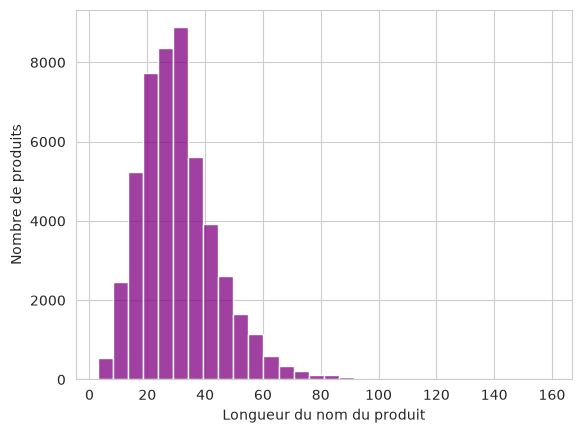

In [32]:
nom_longueur = df["product_name"].str.len()
sns.histplot(nom_longueur, bins=30, color="purple")
plt.xlabel("Longueur du nom du produit")
plt.ylabel("Nombre de produits")
plt.show()